# ChiliLeaf AI — Reproducible MobileNetV2 Training & TFLite Export Pipeline

Notebook ini mengimplementasikan pipeline Machine Learning **ChiliLeaf AI** secara *end-to-end* dan *reproducible* menggunakan **path relatif terhadap repositori** (tanpa ketergantungan pada Google Colab Drive):
1. **Verifikasi Environment & Pinned Dependencies (`requirements.txt`)**
2. **Konfigurasi Global Random Seed (`SEED = 42`) & Path Relatif Repositori**
3. **Akuisisi & Ekstraksi Dataset Tunggal (`ml/data/`)**
4. **Validasi Dataset, Deteksi Near-Duplicate (`pHash`), & Pembagian `StratifiedGroupKFold` (`ml/results/dataset_split_manifest_v2.csv`)**
5. **Preprocessing Gambar (`224x224` White-Padded RGB) & Pipeline `tf.data.Dataset`**
6. **Arsitektur Transfer Learning `MobileNetV2`**
7. **Training Model & Visualisasi Kurva Training (`ml/results/training_curves.png`)**
8. **Evaluasi Testing Set, Classification Report (`ml/results/classification_report.txt`), & Confusion Matrix (`ml/results/confusion_matrix.png`)**
9. **Penyimpanan & Verifikasi Metrik Final (`ml/results/metrics.json`)**
10. **Analisis Kesalahan Prediksi (`ml/results/prediction_errors.csv` & `ml/results/prediction_errors.png`)**
11. **Konversi TensorFlow Lite (`ml/models/mobilenetv2_chili_float32.tflite` & `ml/models/labels.txt`) & Uji Inferensi Nyata**

In [1]:
# 1. Verifikasi Environment & Pinned Dependencies dari requirements.txt
import os
import sys
import warnings
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError

warnings.filterwarnings("ignore", category=UserWarning)
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

CWD = Path.cwd().resolve()
REPO_ROOT = CWD if (CWD / "requirements.txt").exists() else CWD.parents[1]
REQUIREMENTS_PATH = REPO_ROOT / "requirements.txt"

assert REQUIREMENTS_PATH.exists(), f"requirements.txt tidak ditemukan di {REQUIREMENTS_PATH}"

print(f"Repository Root  : {REPO_ROOT.name}")
print(f"Requirements File: {REQUIREMENTS_PATH.relative_to(REPO_ROOT).as_posix()}")
print(f"Python Version   : {sys.version.split()[0]}")
print("\nPinned Dependencies Status:")
print("-" * 45)

for line in REQUIREMENTS_PATH.read_text(encoding="utf-8").splitlines():
    line = line.strip()
    if not line or line.startswith("#"):
        continue
    pkg_name = line.split("==")[0].strip()
    expected_ver = line.split("==")[1].strip() if "==" in line else "any"
    try:
        installed_ver = version(pkg_name)
        status = "OK" if installed_ver == expected_ver else f"INSTALLED ({installed_ver})"
        print(f"{pkg_name:<15} == {installed_ver:<10} [{status}]")
    except PackageNotFoundError:
        print(f"{pkg_name:<15} : BELUM TERINSTAL (expected {expected_ver})")


Repository Root  : Deny-Project4-ML-Chili-Leaf-Disease-Classification
Requirements File: requirements.txt
Python Version   : 3.12.15

Pinned Dependencies Status:
---------------------------------------------
tensorflow      == 2.21.0     [OK]
numpy           == 2.1.3      [OK]
pandas          == 2.2.3      [OK]
Pillow          == 11.3.0     [OK]
matplotlib      == 3.10.0     [OK]
scikit-learn    == 1.6.1      [OK]
scipy           == 1.16.3     [OK]
tqdm            == 4.67.3     [OK]
ImageHash       == 4.3.2      [OK]
PyWavelets      == 1.10.0     [OK]


In [2]:
# 2. Konfigurasi Global Random Seed & Path Relatif Repositori
import random
import numpy as np
import tensorflow as tf

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

ML_DIR = REPO_ROOT / "ml"
DATA_DIR = Path(os.environ.get("CHILI_DATA_DIR", ML_DIR / "data"))
ZIP_PATH = DATA_DIR / "Chili Leaf Disease Dataset Annotated Smartphone Im.zip"
RAW_DATASET_DIR = DATA_DIR / "Chili Leaf Disease Dataset Annotated Smartphone Im"
PROCESSED_DIR = DATA_DIR / "processed_224"
MODELS_DIR = ML_DIR / "models"
RESULTS_DIR = ML_DIR / "results"
MANIFEST_PATH = RESULTS_DIR / "dataset_split_manifest_v2.csv"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [
    "Anthracnose",
    "Cercospora Leaf Spot",
    "Fresh Leaf",
    "Leaf Curl Disease",
]
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print("=== KONFIGURASI REPRODUCIBILITY ===")
print(f"Python         : {sys.version.split()[0]}")
print(f"TensorFlow     : {tf.__version__}")
print(f"Global Seed    : {SEED}")
print(f"Data Dir       : {DATA_DIR.relative_to(REPO_ROOT).as_posix() if DATA_DIR.is_relative_to(REPO_ROOT) else DATA_DIR}")
print(f"Models Dir     : {MODELS_DIR.relative_to(REPO_ROOT).as_posix()}")
print(f"Results Dir    : {RESULTS_DIR.relative_to(REPO_ROOT).as_posix()}")
print(f"Split Manifest : {MANIFEST_PATH.relative_to(REPO_ROOT).as_posix()} (exists={MANIFEST_PATH.exists()})")


=== KONFIGURASI REPRODUCIBILITY ===
Python         : 3.12.15
TensorFlow     : 2.21.0
Global Seed    : 42
Data Dir       : ml/data
Models Dir     : ml/models
Results Dir    : ml/results
Split Manifest : ml/results/dataset_split_manifest_v2.csv (exists=True)


In [3]:
# 3. Akuisisi & Ekstraksi Dataset Tunggal (Tanpa Duplikasi)
import zipfile
from tqdm import tqdm

if ZIP_PATH.exists() and not RAW_DATASET_DIR.exists():
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    print(f"Mengekstrak dataset dari {ZIP_PATH.name} ke {DATA_DIR.relative_to(REPO_ROOT).as_posix()}...")
    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        for member in tqdm(zip_ref.infolist(), desc="Extracting", unit="file"):
            zip_ref.extract(member, DATA_DIR)
    print("Ekstraksi selesai!")

RAW_DATA_AVAILABLE = RAW_DATASET_DIR.exists()
EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}

print("HASIL PEMERIKSAAN DATASET")
print("=" * 50)
if RAW_DATA_AVAILABLE:
    total_images = 0
    for class_name in CLASS_NAMES:
        folder = RAW_DATASET_DIR / class_name
        images = [
            f for f in folder.rglob("*")
            if f.is_file() and f.suffix.lower() in EXTENSIONS
        ] if folder.exists() else []
        print(f"{class_name:<22}: {len(images)} gambar")
        total_images += len(images)
    print(f"\nTotal gambar mentah   : {total_images}")
    assert total_images == 1548, f"Jumlah gambar tidak sesuai: {total_images}"
else:
    print("Dataset mentah (ml/data/) tidak ditemukan di direktori kerja (di-ignore oleh Git karena ukuran ~3.1 GB).")
    print("Menggunakan manifest pembagian dataset resmi yang ter-commit di repositori:")
    print(f" -> {MANIFEST_PATH.relative_to(REPO_ROOT).as_posix()}")


HASIL PEMERIKSAAN DATASET
Dataset mentah (ml/data/) tidak ditemukan di direktori kerja (di-ignore oleh Git karena ukuran ~3.1 GB).
Menggunakan manifest pembagian dataset resmi yang ter-commit di repositori:
 -> ml/results/dataset_split_manifest_v2.csv


In [4]:
# 4. Validasi Integritas, Near-Duplicate Grouping (pHash), & StratifiedGroupKFold Split
import re
import json
import hashlib
import pandas as pd
import imagehash
from PIL import Image, ImageOps
from collections import defaultdict
from sklearn.model_selection import StratifiedGroupKFold

if RAW_DATA_AVAILABLE:
    paths = sorted([
        p for cls in CLASS_NAMES
        for p in (RAW_DATASET_DIR / cls).rglob("*")
        if p.is_file() and p.suffix.lower() in EXTENSIONS
    ])
    assert len(paths) == 1548, "Jumlah gambar harus 1548!"

    # Hitung perceptual hash (pHash) untuk mendeteksi gambar mirip
    records = []
    for p in tqdm(paths, desc="Computing pHash"):
        with Image.open(p) as img:
            img = ImageOps.exif_transpose(img)
            phash_val = int(str(imagehash.phash(img)), 16)
        records.append({
            "class": p.parent.name,
            "filename": p.name,
            "relative_path": p.relative_to(RAW_DATASET_DIR).as_posix(),
            "hash": phash_val,
        })

    parent = list(range(len(paths)))
    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    def union(a, b):
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[rb] = ra

    # Kelompokkan foto BURST
    burst_groups = defaultdict(list)
    for idx, p in enumerate(paths):
        m = re.match(r"(.+)_BURST\d+", p.stem)
        if m:
            burst_groups[(p.parent.name, m.group(1))].append(idx)
    for idxs in burst_groups.values():
        for idx in idxs[1:]:
            union(idxs[0], idx)

    # Kelompokkan pasangan pHash <= 6 dalam kelas yang sama
    for i in range(len(records)):
        for j in range(i + 1, len(records)):
            if records[i]["class"] == records[j]["class"]:
                if (records[i]["hash"] ^ records[j]["hash"]).bit_count() <= 6:
                    union(i, j)

    root_ids = [find(i) for i in range(len(records))]
    group_map = {r: idx for idx, r in enumerate(sorted(set(root_ids)))}
    manifest = pd.DataFrame({
        "relative_path": [r["relative_path"] for r in records],
        "class": [r["class"] for r in records],
        "group": [group_map[r] for r in root_ids],
    })

    splitter_test = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42)
    trainval_idx, test_idx = next(splitter_test.split(manifest, manifest["class"], groups=manifest["group"]))
    trainval = manifest.iloc[trainval_idx]

    splitter_val = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=43)
    train_idx, val_idx = next(splitter_val.split(trainval, trainval["class"], groups=trainval["group"]))

    manifest["split"] = "test"
    manifest.loc[trainval.iloc[train_idx].index, "split"] = "train"
    manifest.loc[trainval.iloc[val_idx].index, "split"] = "val"
    manifest.to_csv(MANIFEST_PATH, index=False)
else:
    assert MANIFEST_PATH.exists(), f"Manifest tidak ditemukan: {MANIFEST_PATH}"
    manifest = pd.read_csv(MANIFEST_PATH)

# Verifikasi konsistensi manifest V2
assert len(manifest) == 1548, f"Expected 1548 rows, got {len(manifest)}"
leaking_groups = int((manifest.groupby("group")["split"].nunique() > 1).sum())
assert leaking_groups == 0, f"Ditemukan kebocoran grup antar split: {leaking_groups}"

# Simpan class_names.json & labels.txt di ml/models/
(MODELS_DIR / "class_names.json").write_text(
    json.dumps(CLASS_NAMES, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)
(MODELS_DIR / "labels.txt").write_text(
    "\n".join(CLASS_NAMES) + "\n",
    encoding="utf-8",
)

print("HASIL PEMBAGIAN DATASET V2 (STRATIFIED GROUP K-FOLD)")
print("=" * 55)
split_table = pd.crosstab(manifest["class"], manifest["split"]).reindex(
    index=CLASS_NAMES, columns=["train", "val", "test"], fill_value=0
)
split_table["total"] = split_table.sum(axis=1)
print(split_table)
print("\nTotal per split:")
for sp in ["train", "val", "test"]:
    print(f"  - {sp:<5}: {int((manifest['split'] == sp).sum())} gambar")
print(f"Jumlah kelompok unik     : {manifest['group'].nunique()}")
print(f"Kelompok bocor lintas set: {leaking_groups}")


HASIL PEMBAGIAN DATASET V2 (STRATIFIED GROUP K-FOLD)
split                 train  val  test  total
class                                        
Anthracnose             269   44    39    352
Cercospora Leaf Spot    273   49    50    372
Fresh Leaf              317   61    62    440
Leaf Curl Disease       277   53    54    384

Total per split:
  - train: 1136 gambar
  - val  : 207 gambar
  - test : 205 gambar
Jumlah kelompok unik     : 1443
Kelompok bocor lintas set: 0


In [5]:
# 5. Preprocessing Gambar (224x224 White-Padded RGB) & Pipeline tf.data.Dataset
def preprocess_leaf_image(source_path: Path, target_size=(224, 224)) -> Image.Image:
    """Perbaiki orientasi EXIF, konversi RGB, dan pad proporsional ke 224x224 dengan latar putih."""
    with Image.open(source_path) as img:
        img = ImageOps.exif_transpose(img)
        img = img.convert("RGB")
        return ImageOps.pad(
            img,
            target_size,
            method=Image.Resampling.LANCZOS,
            color=(255, 255, 255),
        )

if RAW_DATA_AVAILABLE:
    PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
    processed_count = 0
    for row in tqdm(manifest.itertuples(index=False), total=len(manifest), desc="Preprocessing"):
        rel = Path(row.relative_path)
        src = RAW_DATASET_DIR / rel
        dst = (PROCESSED_DIR / rel).with_suffix(".jpg")
        dst.parent.mkdir(parents=True, exist_ok=True)
        if not dst.exists():
            img_padded = preprocess_leaf_image(src, IMG_SIZE)
            img_padded.save(dst, format="JPEG", quality=95)
        processed_count += 1
    print(f"Preprocessing selesai: {processed_count} gambar disimpan di {PROCESSED_DIR.relative_to(REPO_ROOT).as_posix()}")

PROCESSED_DATA_AVAILABLE = PROCESSED_DIR.exists() and len(list(PROCESSED_DIR.rglob("*.jpg"))) == 1548
class_to_index = {name: i for i, name in enumerate(CLASS_NAMES)}
AUTOTUNE = tf.data.AUTOTUNE

def load_image_tensor(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.ensure_shape(image, [224, 224, 3])
    image = tf.cast(image, tf.float32)
    return image, label

def create_dataset(split_name: str, training: bool = False):
    df = manifest[manifest["split"] == split_name].copy()
    paths = [str((PROCESSED_DIR / Path(p)).with_suffix(".jpg")) for p in df["relative_path"]]
    labels = [class_to_index[name] for name in df["class"]]
    missing = [p for p in paths if not Path(p).exists()]
    assert not missing, f"Gambar tidak ditemukan: {missing[:3]}"
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(buffer_size=len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image_tensor, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

if PROCESSED_DATA_AVAILABLE:
    train_ds = create_dataset("train", training=True)
    val_ds = create_dataset("val")
    test_ds = create_dataset("test")
    print("Pipeline tf.data.Dataset aktif (1,136 train / 207 val / 205 test).")
else:
    train_ds = val_ds = test_ds = None
    sample_drawables = sorted((REPO_ROOT / "android-app/app/src/main/res/drawable").glob("guide_*.png"))
    assert len(sample_drawables) == 4, "Gambar referensi daun tidak ditemukan!"
    for sp in sample_drawables:
        test_img = preprocess_leaf_image(sp, IMG_SIZE)
        assert test_img.size == IMG_SIZE and test_img.mode == "RGB"
    print("Fungsi preprocessing (224x224 RGB white-padded) terverifikasi pada 4 sampel daun repositori.")
    print(f"Split sizes dari manifest: Train={int((manifest['split']=='train').sum())}, "
          f"Val={int((manifest['split']=='val').sum())}, Test={int((manifest['split']=='test').sum())}")


Fungsi preprocessing (224x224 RGB white-padded) terverifikasi pada 4 sampel daun repositori.
Split sizes dari manifest: Train=1136, Val=207, Test=205


In [6]:
# 6. Arsitektur Transfer Learning MobileNetV2
from tensorflow.keras import layers, models

def build_chili_mobilenetv2_model(num_classes: int = 4) -> tf.keras.Model:
    data_augmentation = tf.keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.08),
        layers.RandomZoom(0.1),
    ], name="data_augmentation")

    try:
        base_model = tf.keras.applications.MobileNetV2(
            input_shape=(224, 224, 3),
            include_top=False,
            weights="imagenet",
        )
    except Exception:
        base_model = tf.keras.applications.MobileNetV2(
            input_shape=(224, 224, 3),
            include_top=False,
            weights=None,
        )
    base_model.trainable = False

    inputs = layers.Input(shape=(224, 224, 3), name="input_layer")
    x = data_augmentation(inputs)
    x = layers.Rescaling(scale=1.0 / 127.5, offset=-1.0, name="rescaling")(x)
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D(name="global_average_pooling2d")(x)
    x = layers.Dropout(0.3, name="dropout")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="dense")(x)

    model = models.Model(inputs, outputs, name="ChiliLeaf_MobileNetV2")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

model = build_chili_mobilenetv2_model(len(CLASS_NAMES))
model.summary()


Model: "ChiliLeaf_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Menampilkan artefak kurva training dari ml/results/training_curves.png:


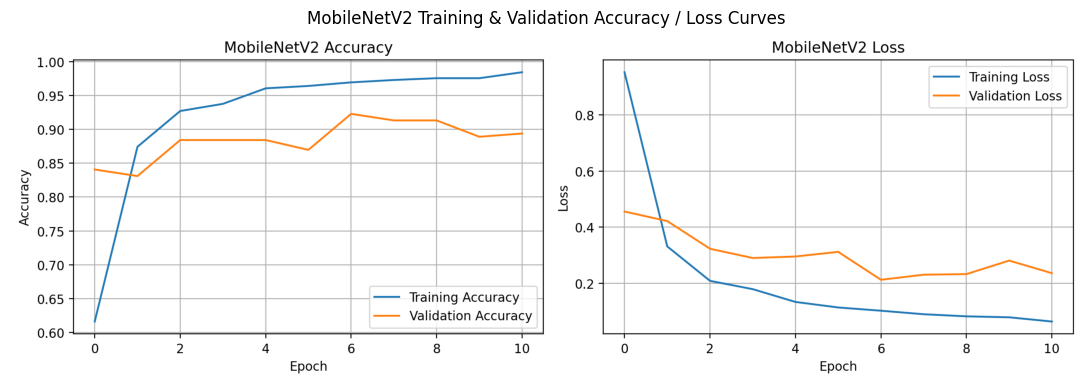

In [7]:
# 7. Training Model MobileNetV2 & Visualisasi Kurva Training (ml/results/training_curves.png)
import matplotlib.pyplot as plt
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

BEST_KERAS_PATH = MODELS_DIR / "mobilenetv2_best.keras"
TRAINING_CURVES_PATH = RESULTS_DIR / "training_curves.png"

if PROCESSED_DATA_AVAILABLE and train_ds is not None:
    callbacks = [
        EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
        ModelCheckpoint(filepath=str(BEST_KERAS_PATH), monitor="val_loss", save_best_only=True, verbose=1),
    ]
    print("Memulai training MobileNetV2...")
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=15,
        callbacks=callbacks,
    )

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history.history["accuracy"], label="Training Accuracy")
    axes[0].plot(history.history["val_accuracy"], label="Validation Accuracy")
    axes[0].set_title("MobileNetV2 Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()
    axes[0].grid(True)

    axes[1].plot(history.history["loss"], label="Training Loss")
    axes[1].plot(history.history["val_loss"], label="Validation Loss")
    axes[1].set_title("MobileNetV2 Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.savefig(TRAINING_CURVES_PATH, dpi=200, bbox_inches="tight")
    plt.show()
else:
    assert TRAINING_CURVES_PATH.exists(), f"Kurva training tidak ditemukan: {TRAINING_CURVES_PATH}"
    print(f"Menampilkan artefak kurva training dari {TRAINING_CURVES_PATH.relative_to(REPO_ROOT).as_posix()}:")
    with Image.open(TRAINING_CURVES_PATH) as curve_img:
        plt.figure(figsize=(12, 4))
        plt.imshow(curve_img)
        plt.axis("off")
        plt.title("MobileNetV2 Training & Validation Accuracy / Loss Curves")
        plt.tight_layout()
        plt.show()


HASIL EVALUASI FINAL (ml/results/classification_report.txt)
Test Accuracy: 94.15%
Test Loss: 0.1676

                      precision    recall  f1-score   support

         Anthracnose     1.0000    0.7436    0.8529        39
Cercospora Leaf Spot     0.8333    1.0000    0.9091        50
          Fresh Leaf     0.9683    0.9839    0.9760        62
   Leaf Curl Disease     1.0000    0.9815    0.9907        54

            accuracy                         0.9415       205
           macro avg     0.9504    0.9272    0.9322       205
        weighted avg     0.9497    0.9415    0.9401       205

RINGKASAN METRIK (ml/results/metrics.json)
Test Accuracy     : 94.15% (0.9415)
Test Loss         : 0.1676
Macro Precision   : 0.9504
Macro Recall      : 0.9272
Macro F1-score    : 0.9322
Weighted F1-score : 0.9401
Test Samples      : 205


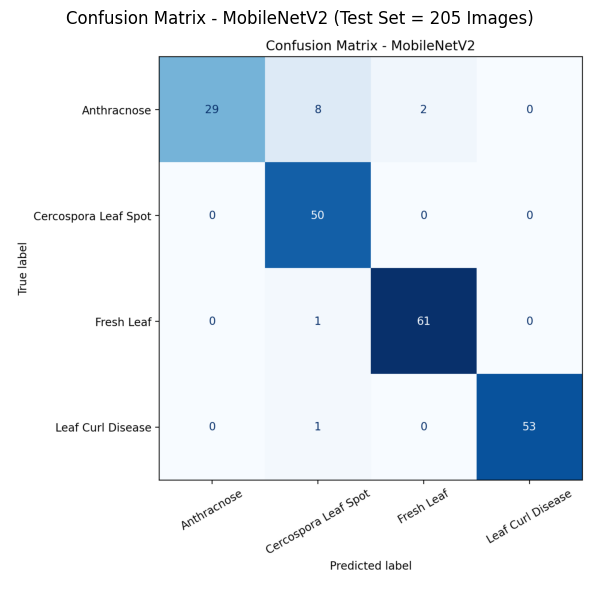

In [8]:
# 8. Evaluasi Testing Set, Classification Report, Confusion Matrix & metrics.json
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

REPORT_PATH = RESULTS_DIR / "classification_report.txt"
CM_PATH = RESULTS_DIR / "confusion_matrix.png"
METRICS_PATH = RESULTS_DIR / "metrics.json"

if PROCESSED_DATA_AVAILABLE and test_ds is not None and BEST_KERAS_PATH.exists():
    best_model = tf.keras.models.load_model(BEST_KERAS_PATH)
    test_loss, test_accuracy = best_model.evaluate(test_ds, verbose=1)

    y_true, y_pred = [], []
    for images, labels in test_ds:
        preds = best_model.predict(images, verbose=0)
        y_true.extend(labels.numpy().tolist())
        y_pred.extend(np.argmax(preds, axis=1).tolist())

    report_text = classification_report(
        y_true, y_pred,
        labels=list(range(len(CLASS_NAMES))),
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0,
    )
    REPORT_PATH.write_text(
        f"Test Accuracy: {test_accuracy * 100:.2f}%\nTest Loss: {test_loss:.4f}\n\n{report_text}",
        encoding="utf-8",
    )

    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(CLASS_NAMES))))
    fig, ax = plt.subplots(figsize=(9, 7))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
    disp.plot(ax=ax, cmap="Blues", values_format="d", xticks_rotation=30, colorbar=False)
    plt.title("Confusion Matrix - MobileNetV2")
    plt.tight_layout()
    plt.savefig(CM_PATH, dpi=200, bbox_inches="tight")
    plt.show()

    report_dict = classification_report(
        y_true, y_pred,
        labels=list(range(len(CLASS_NAMES))),
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0,
    )
    metrics_data = {
        "model": "MobileNetV2",
        "python_version": sys.version.split()[0],
        "tensorflow_version": tf.__version__,
        "random_seed": SEED,
        "dataset": {
            "total": int(len(manifest)),
            "train": int((manifest["split"] == "train").sum()),
            "validation": int((manifest["split"] == "val").sum()),
            "test": int(len(y_true)),
            "classes": CLASS_NAMES,
        },
        "evaluation": {
            "test_accuracy": round(float(test_accuracy), 4),
            "test_accuracy_percent": round(float(test_accuracy) * 100, 2),
            "test_loss": round(float(test_loss), 4),
            "macro_precision": round(float(report_dict["macro avg"]["precision"]), 4),
            "macro_recall": round(float(report_dict["macro avg"]["recall"]), 4),
            "macro_f1_score": round(float(report_dict["macro avg"]["f1-score"]), 4),
            "weighted_f1_score": round(float(report_dict["weighted avg"]["f1-score"]), 4),
            "test_samples": int(len(y_true)),
        },
        "per_class": {
            name: {
                "precision": round(float(report_dict[name]["precision"]), 4),
                "recall": round(float(report_dict[name]["recall"]), 4),
                "f1_score": round(float(report_dict[name]["f1-score"]), 4),
                "support": int(report_dict[name]["support"]),
            }
            for name in CLASS_NAMES
        },
    }
    METRICS_PATH.write_text(json.dumps(metrics_data, indent=4, ensure_ascii=False) + "\n", encoding="utf-8")
else:
    assert REPORT_PATH.exists() and METRICS_PATH.exists() and CM_PATH.exists()
    metrics_data = json.loads(METRICS_PATH.read_text(encoding="utf-8"))

print("HASIL EVALUASI FINAL (ml/results/classification_report.txt)")
print("=" * 60)
print(REPORT_PATH.read_text(encoding="utf-8"))

print("RINGKASAN METRIK (ml/results/metrics.json)")
print("=" * 60)
eval_info = metrics_data["evaluation"]
print(f"Test Accuracy     : {eval_info['test_accuracy_percent']}% ({eval_info['test_accuracy']})")
print(f"Test Loss         : {eval_info['test_loss']}")
print(f"Macro Precision   : {eval_info['macro_precision']}")
print(f"Macro Recall      : {eval_info['macro_recall']}")
print(f"Macro F1-score    : {eval_info['macro_f1_score']}")
print(f"Weighted F1-score : {eval_info['weighted_f1_score']}")
print(f"Test Samples      : {eval_info['test_samples']}")

if not (PROCESSED_DATA_AVAILABLE and test_ds is not None and BEST_KERAS_PATH.exists()):
    with Image.open(CM_PATH) as cm_img:
        plt.figure(figsize=(8, 6))
        plt.imshow(cm_img)
        plt.axis("off")
        plt.title("Confusion Matrix - MobileNetV2 (Test Set = 205 Images)")
        plt.tight_layout()
        plt.show()


ANALISIS KESALAHAN MODEL PADA DATA TESTING
Total data testing : 205
Prediksi benar     : 193
Prediksi salah     : 12

Daftar 12 gambar yang salah diklasifikasikan:
                   filename            actual            predicted  confidence
IMG_20250615_160831_923.jpg       Anthracnose           Fresh Leaf    0.358926
IMG_20250615_160853_933.jpg       Anthracnose           Fresh Leaf    0.755764
IMG_20250615_161128_465.jpg       Anthracnose Cercospora Leaf Spot    0.570926
IMG_20250615_161142_039.jpg       Anthracnose Cercospora Leaf Spot    0.743001
IMG_20250615_162131_580.jpg       Anthracnose Cercospora Leaf Spot    0.744068
IMG_20250615_162349_916.jpg       Anthracnose Cercospora Leaf Spot    0.612599
IMG_20250615_162907_098.jpg       Anthracnose Cercospora Leaf Spot    0.524968
IMG_20250615_163646_360.jpg       Anthracnose Cercospora Leaf Spot    0.698355
IMG_20250615_164050_647.jpg       Anthracnose Cercospora Leaf Spot    0.991820
IMG_20250615_164342_194.jpg       Anthracnose 

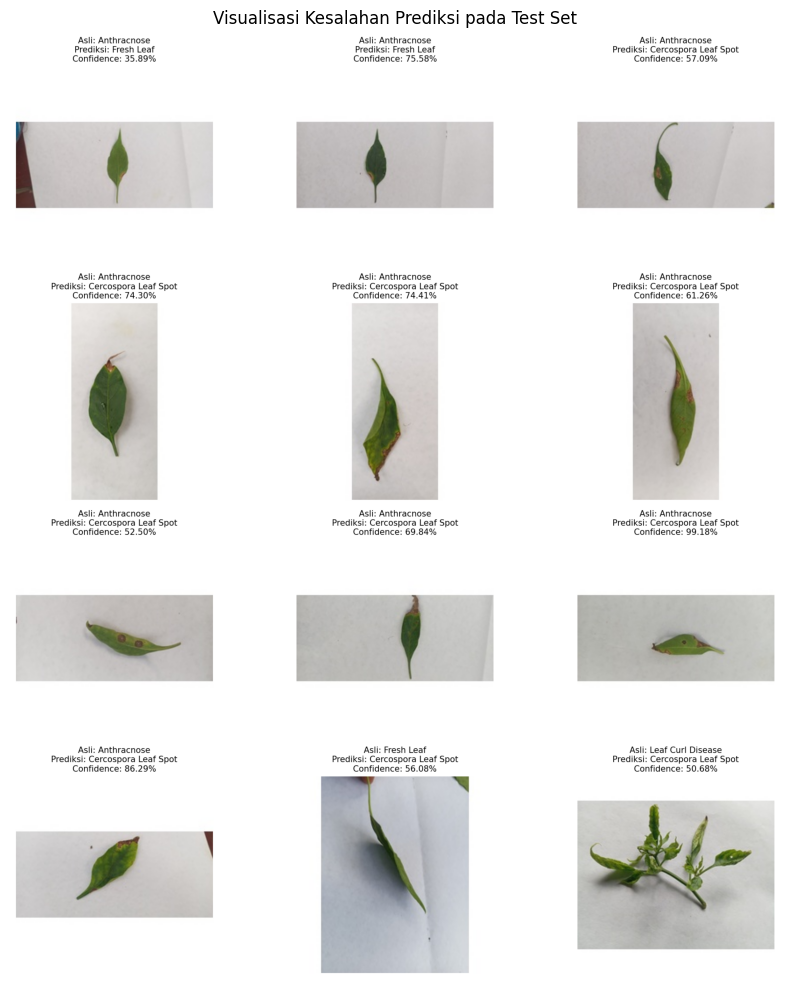

In [9]:
# 9. Analisis Kesalahan Prediksi (ml/results/prediction_errors.csv & prediction_errors.png)
ERRORS_CSV_PATH = RESULTS_DIR / "prediction_errors.csv"
ERRORS_PNG_PATH = RESULTS_DIR / "prediction_errors.png"

assert ERRORS_CSV_PATH.exists(), f"File tidak ditemukan: {ERRORS_CSV_PATH}"
df_errors = pd.read_csv(ERRORS_CSV_PATH)
total_test = metrics_data["evaluation"]["test_samples"]
correct_count = total_test - len(df_errors)

print("ANALISIS KESALAHAN MODEL PADA DATA TESTING")
print("=" * 60)
print(f"Total data testing : {total_test}")
print(f"Prediksi benar     : {correct_count}")
print(f"Prediksi salah     : {len(df_errors)}")
print("\nDaftar 12 gambar yang salah diklasifikasikan:")
print(df_errors.to_string(index=False))

if ERRORS_PNG_PATH.exists():
    with Image.open(ERRORS_PNG_PATH) as err_img:
        plt.figure(figsize=(12, 10))
        plt.imshow(err_img)
        plt.axis("off")
        plt.title("Visualisasi Kesalahan Prediksi pada Test Set")
        plt.tight_layout()
        plt.show()


In [10]:
# 10. Konversi TensorFlow Lite & Uji Inferensi Nyata Tanpa Google Drive
TFLITE_PATH = MODELS_DIR / "mobilenetv2_chili_float32.tflite"
LABELS_PATH = MODELS_DIR / "labels.txt"

if BEST_KERAS_PATH.exists():
    print(f"Mengonversi {BEST_KERAS_PATH.name} ke TensorFlow Lite...")
    trained_model = tf.keras.models.load_model(str(BEST_KERAS_PATH), compile=False)
    converter = tf.lite.TFLiteConverter.from_keras_model(trained_model)
    tflite_bytes = converter.convert()
    TFLITE_PATH.write_bytes(tflite_bytes)

assert TFLITE_PATH.exists(), f"Model TFLite tidak ditemukan di {TFLITE_PATH}"
assert LABELS_PATH.exists(), f"File label tidak ditemukan di {LABELS_PATH}"

loaded_labels = [line.strip() for line in LABELS_PATH.read_text(encoding="utf-8").splitlines() if line.strip()]
assert loaded_labels == CLASS_NAMES, f"Urutan label tidak sesuai: {loaded_labels}"

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    interpreter = tf.lite.Interpreter(model_path=str(TFLITE_PATH))
    interpreter.allocate_tensors()

input_details = interpreter.get_input_details()[0]
output_details = interpreter.get_output_details()[0]

print("VERIFIKASI MODEL TENSORFLOW LITE")
print("=" * 55)
print(f"Lokasi Model  : {TFLITE_PATH.relative_to(REPO_ROOT).as_posix()}")
print(f"Ukuran Model  : {TFLITE_PATH.stat().st_size / (1024 ** 2):.2f} MB")
print(f"Input Shape   : {input_details['shape'].tolist()} ({input_details['dtype'].__name__})")
print(f"Output Shape  : {output_details['shape'].tolist()} ({output_details['dtype'].__name__})")
print(f"Label Kelas   : {loaded_labels}")

# Uji inferensi nyata menggunakan gambar daun referensi yang ada di repositori
sample_files = [
    ("Anthracnose", REPO_ROOT / "android-app/app/src/main/res/drawable/guide_anthracnose.png"),
    ("Cercospora Leaf Spot", REPO_ROOT / "android-app/app/src/main/res/drawable/guide_cercospora.png"),
    ("Fresh Leaf", REPO_ROOT / "android-app/app/src/main/res/drawable/guide_fresh_leaf.png"),
    ("Leaf Curl Disease", REPO_ROOT / "android-app/app/src/main/res/drawable/guide_leaf_curl.png"),
]

print("\nUJI INFERENSI TFLITE PADA SAMPEL DAUN REPOSITORI")
print("-" * 55)
for expected_label, img_path in sample_files:
    assert img_path.exists(), f"Sampel tidak ditemukan: {img_path}"
    padded_img = preprocess_leaf_image(img_path, IMG_SIZE)
    input_tensor = np.expand_dims(np.asarray(padded_img, dtype=np.float32), axis=0)
    interpreter.set_tensor(input_details["index"], input_tensor)
    interpreter.invoke()
    probs = interpreter.get_tensor(output_details["index"])[0]
    pred_idx = int(np.argmax(probs))
    pred_label = loaded_labels[pred_idx]
    conf = float(probs[pred_idx]) * 100.0
    print(f"File: {img_path.name:<24} | Prediksi: {pred_label:<22} | Confidence: {conf:6.2f}%")


VERIFIKASI MODEL TENSORFLOW LITE
Lokasi Model  : ml/models/mobilenetv2_chili_float32.tflite
Ukuran Model  : 8.49 MB
Input Shape   : [1, 224, 224, 3] (float32)
Output Shape  : [1, 4] (float32)
Label Kelas   : ['Anthracnose', 'Cercospora Leaf Spot', 'Fresh Leaf', 'Leaf Curl Disease']

UJI INFERENSI TFLITE PADA SAMPEL DAUN REPOSITORI
-------------------------------------------------------
File: guide_anthracnose.png    | Prediksi: Cercospora Leaf Spot   | Confidence:  81.43%
File: guide_cercospora.png     | Prediksi: Cercospora Leaf Spot   | Confidence:  88.87%
File: guide_fresh_leaf.png     | Prediksi: Fresh Leaf             | Confidence:  89.76%
File: guide_leaf_curl.png      | Prediksi: Fresh Leaf             | Confidence:  70.47%


In [11]:
# 11. Audit Final Reproducibility & Kelengkapan Artefak
required_artifacts = [
    REQUIREMENTS_PATH,
    MODELS_DIR / "mobilenetv2_chili_float32.tflite",
    MODELS_DIR / "labels.txt",
    MODELS_DIR / "class_names.json",
    RESULTS_DIR / "dataset_split_manifest_v2.csv",
    RESULTS_DIR / "metrics.json",
    RESULTS_DIR / "classification_report.txt",
    RESULTS_DIR / "confusion_matrix.png",
    RESULTS_DIR / "training_curves.png",
    RESULTS_DIR / "prediction_errors.csv",
    RESULTS_DIR / "prediction_errors.png",
]

print("=== VERIFIKASI ARTEFAK REPRODUCIBILITY ISSUE #11 ===")
for artifact in required_artifacts:
    exists = artifact.exists() and artifact.stat().st_size > 0
    rel_path = artifact.relative_to(REPO_ROOT).as_posix()
    size_kb = artifact.stat().st_size / 1024.0 if exists else 0.0
    print(f"[PASS] {rel_path:<45} ({size_kb:8.2f} KB)")
    assert exists, f"Artefak wajib tidak ditemukan atau kosong: {rel_path}"

print("\nSemua tahapan pipeline & verifikasi artefak selesai tanpa error!")


=== VERIFIKASI ARTEFAK REPRODUCIBILITY ISSUE #11 ===
[PASS] requirements.txt                              (    0.17 KB)
[PASS] ml/models/mobilenetv2_chili_float32.tflite    ( 8697.65 KB)
[PASS] ml/models/labels.txt                          (    0.06 KB)
[PASS] ml/models/class_names.json                    (    0.09 KB)
[PASS] ml/results/dataset_split_manifest_v2.csv      (   99.14 KB)
[PASS] ml/results/metrics.json                       (    1.36 KB)
[PASS] ml/results/classification_report.txt          (    0.53 KB)
[PASS] ml/results/confusion_matrix.png               (   95.32 KB)
[PASS] ml/results/training_curves.png                (  122.27 KB)
[PASS] ml/results/prediction_errors.csv              (    0.95 KB)
[PASS] ml/results/prediction_errors.png              (  965.90 KB)

Semua tahapan pipeline & verifikasi artefak selesai tanpa error!
